# Açıklanabilir Kredi Risk Skorlama Modeli

Bir kişinin 2 yıl içinde ciddi ödeme sıkıntısına (temerrüt) düşme olasılığını tahmin eden ve kararını **açıklayabilen** bir kredi skorlama modeli.

**Veri:** Give Me Some Credit (`cs-training.csv`) - 150.000 müşteri, 10 özellik. **Hedef:** `SeriousDlqin2yrs` (1=temerrüt, 0=yok, ~%6.7 dengesiz). *Sınıflandırma* problemi.

**Bu projenin gösterdikleri:**
- Veri kalitesi denetimi (DebtRatio'nun bozukluğunu tespit + kanıt + düzeltme)
- IV ile feature selection (klasik kredi skorlama) - SHAP ile çapraz doğrulama
- Dengesiz veri (class_weight / scale_pos_weight)
- Kredi metrikleri: KS, Gini, PR-AUC
- Baseline → güçlü model (Logistic → XGBoost)
- **SHAP + LLM ile sade Türkçe red gerekçesi** (ayrıştırıcı katman)
- MLflow ile deney takibi

**Akış:** 1) Yükle → 2) Veri kalitesi & temizlik → 3) IV → 4) Train/test → 5) Logistic → 6) Metrikler → 7) Threshold → 8) XGBoost → 9) SHAP → 10) LLM → 11) MLflow

## 1. Veriyi yükle ve incele

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("cs-training.csv", index_col=0)
print("Boyut:", df.shape)
print(df["SeriousDlqin2yrs"].value_counts(normalize=True))   # ~%6.7 temerrüt
print()
print(df.isnull().sum())   # MonthlyIncome (~%20) ve NumberOfDependents eksik

Boyut: (150000, 11)
SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64

SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64


**Bulgu:** Hedef dengesiz (~%6.7 temerrüt) → accuracy yanıltıcı olur, KS/PR-AUC/Recall kullanacağız. İki sütunda eksik veri var.

## 2. Veri Kalitesi Denetimi & Temizlik

### 2a. DebtRatio neden bozuk?
`DebtRatio` borç/gelir oranı olmalı (0-1 civarı) ama `describe()` maksimumu **329.664** gösteriyor - imkansız. Nedenini körlemesine kırpmadan araştırıyoruz: yüksek DebtRatio'lu kişilerde gelir eksik mi?

In [2]:
print(df["DebtRatio"].describe())

yuksek = df[df["DebtRatio"] > df["DebtRatio"].quantile(0.95)]
print(f"\nEn yüksek %5 DebtRatio'lu kişilerde gelir EKSİK olan oranı: "
      f"{yuksek['MonthlyIncome'].isnull().mean():.1%}")

count    150000.000000
mean        353.005076
std        2037.818523
min           0.000000
25%           0.175074
50%           0.366508
75%           0.868254
max      329664.000000
Name: DebtRatio, dtype: float64

En yüksek %5 DebtRatio'lu kişilerde gelir EKSİK olan oranı: 94.9%


**Bulgu:** En yüksek %5 DebtRatio'lu kişilerin **%94.9'unun geliri eksik.** Yani DebtRatio, gelir bilgisi olmayan satırlarda "oran" olmaktan çıkıp anlamsız bir sayıya dönüşmüş. Bozukluk rastgele değil, gelir eksikliğiyle sistematik olarak bağlı.

### 2b. Eksik doldurma (imputation)
Boş hücreleri **medyan** ile dolduruyoruz.

Aykırı değerlere dayanıklı (ortalama olsa uçuk gelirler bozardı).

In [3]:
X = df.drop("SeriousDlqin2yrs", axis=1)
y = df["SeriousDlqin2yrs"]

X["MonthlyIncome"] = X["MonthlyIncome"].fillna(X["MonthlyIncome"].median())
X["NumberOfDependents"] = X["NumberOfDependents"].fillna(X["NumberOfDependents"].median())
print("Eksik kalan:", X.isnull().sum().sum())

Eksik kalan: 0


### 2c. Aykırı değer temizliği (capping) - iki sütun, iki yöntem
- **DebtRatio:** istatistiksel `quantile(0.99)` işe yaramadı (4979 çıkıyor, çünkü verinin çoğu bozuk). **Domain mantığı:** borç/gelir oranı ~2'yi geçmemeli → 2'ye kırpıyoruz.
- **RevolvingUtilization:** burada %99'luk eşik makul (~1.09) → onu kullanıyoruz.

Her sorunun kendine uygun çözümü var ve körü körüne aynı yöntemi uygulamıyoruz.

In [4]:
X["DebtRatio"] = X["DebtRatio"].clip(upper=2)

rev = "RevolvingUtilizationOfUnsecuredLines"
X[rev] = X[rev].clip(upper=X[rev].quantile(0.99))

print("DebtRatio yeni max:", round(X["DebtRatio"].max(), 2))
print("RevolvingUtilization yeni max:", round(X[rev].max(), 2))

DebtRatio yeni max: 2.0
RevolvingUtilization yeni max: 1.09


**Not:** Bu temizliğin etkisini birazdan Bölüm 6'da göreceğiz. Baseline modelin KS'i **0.46 → 0.51** çıkıyor. Yani veri denetimi ölçülebilir fayda sağlıyor.

## 3. IV ile Feature Selection (klasik kredi skorlama)

**IV (Information Value):** bir özelliğin temerrüdü tahmin etme gücünü ölçen tek sayı - bankaların onlarca yıldır kullandığı klasik yöntem.

| IV | Anlam |
|----|-------|
| < 0.02 | işe yaramaz |
| 0.02–0.1 | zayıf |
| 0.1–0.3 | orta |
| 0.3–0.5 | güçlü |
| > 0.5 | şüpheli (leakage kontrol et) |

Hesap: özelliği gruplara böl → her grupta iyi/kötü oranı → **WOE** (grubun risk ağırlığı) → IV = katkıların toplamı.

In [5]:
def calculate_iv(data, feature, target, bins=10):
    d = data[[feature, target]].copy()
    if d[feature].nunique() > bins:
        d["grup"] = pd.qcut(d[feature], q=bins, duplicates="drop")
    else:
        d["grup"] = d[feature]
    g = d.groupby("grup", observed=True)[target].agg(["count", "sum"])
    g.columns = ["toplam", "kotu"]
    g["iyi"] = g["toplam"] - g["kotu"]
    g["kotu"] = g["kotu"].replace(0, 0.5)
    g["iyi"]  = g["iyi"].replace(0, 0.5)
    g["kotu_pay"] = g["kotu"] / g["kotu"].sum()
    g["iyi_pay"]  = g["iyi"]  / g["iyi"].sum()
    g["woe"] = np.log(g["iyi_pay"] / g["kotu_pay"])
    g["iv"]  = (g["iyi_pay"] - g["kotu_pay"]) * g["woe"]
    return g["iv"].sum()

veri = pd.concat([X, y], axis=1)
iv_scores = {c: calculate_iv(veri, c, "SeriousDlqin2yrs") for c in X.columns}
iv_df = (pd.DataFrame(iv_scores.items(), columns=["ozellik", "IV"])
           .sort_values("IV", ascending=False))
print(iv_df.to_string(index=False))

secili = iv_df[iv_df["IV"] > 0.1]["ozellik"].tolist()
print("\nIV > 0.1 (güçlü):", secili)

                             ozellik       IV
RevolvingUtilizationOfUnsecuredLines 1.113378
NumberOfTime30-59DaysPastDueNotWorse 0.471831
                                 age 0.259158
                       MonthlyIncome 0.066954
     NumberOfOpenCreditLinesAndLoans 0.066892
                           DebtRatio 0.025345
                  NumberOfDependents 0.024965
        NumberRealEstateLoansOrLines 0.012091
             NumberOfTimes90DaysLate 0.000000
NumberOfTime60-89DaysPastDueNotWorse 0.000000

IV > 0.1 (güçlü): ['RevolvingUtilizationOfUnsecuredLines', 'NumberOfTime30-59DaysPastDueNotWorse', 'age']


**Bulgu 1 - doğrulama:** IV en güçlü olarak `RevolvingUtilization` (1.11), `30-59 gün gecikme` (0.47), `age` (0.26) diyor. Bu, Bölüm 9'daki SHAP grafiğiyle **örtüşüyor** — klasik (IV) ve modern (SHAP) iki bağımsız yöntem aynı özellikleri işaret etti.

**Bulgu 2 - ilginç tutarsızlık:** `NumberOfTimes90DaysLate` ve `60-89 gün gecikme` IV'de **0.000** çıktı, ama SHAP'ta bunlar en önemli faktörler arasında. Neden? Bu özellikler aşırı sıfır-ağırlıklı (insanların ~%98'i 0). IV'nin basit binning'i böyle veriyi ölçemiyor; ağaç tabanlı XGBoost+SHAP ölçebiliyor. İki yöntem çelişince körü körüne birine güvenmedik nedenini anlamaya çalıştık.

**Karar:** XGBoost için özellik SİLMİYORUZ (ağaç modeli zayıf özellikleri zaten göz ardı eder). IV'yi doğrulama olarak kullanıp tüm özelliklerle devam ediyoruz.

## 4. Eğitim / test ayrımı
%80/%20, `stratify=y` ile dengesizliği koruyarak. **Temizlikten sonra** çalışıyor böylece bölünmüş veri de temiz.

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Eğitim:", X_train.shape, "| Test:", X_test.shape)

Eğitim: (120000, 10) | Test: (30000, 10)


## 5. Baseline - Logistic Regression
Ölçekleme (lojistik regresyon ölçeğe duyarlı; `fit` sadece train'de = leakage önleme). `class_weight="balanced"` dengesizliği ele alır.

In [7]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)
y_proba = model.predict_proba(X_test_scaled)[:, 1]
print("Baseline eğitildi. İlk 5 olasılık:", y_proba[:5].round(3))

Baseline eğitildi. İlk 5 olasılık: [0.17  0.314 0.163 0.211 0.214]


## 6. Değerlendirme - Kredi Metrikleri
AUC · Gini (2×AUC−1) · PR-AUC (taban=temerrüt oranı ~0.067) · KS (0.40+ iyi) · Recall.

In [8]:
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score
from scipy.stats import ks_2samp

def kredi_metrik(y_true, y_prob, ad):
    a = roc_auc_score(y_true, y_prob); k = ks_2samp(y_prob[y_true==1], y_prob[y_true==0]).statistic
    print(f"{ad:20s} | AUC {a:.3f} | Gini {2*a-1:.3f} | PR-AUC {average_precision_score(y_true,y_prob):.3f} | KS {k:.3f}")

kredi_metrik(y_test, y_proba, "Logistic (baseline)")
print("Recall @0.50:", round(recall_score(y_test, (y_proba>=0.5).astype(int)), 3))

Logistic (baseline)  | AUC 0.834 | Gini 0.668 | PR-AUC 0.335 | KS 0.509
Recall @0.50: 0.745


**Bulgu — temizliğin etkisi:** Temizlik sonrası baseline AUC **0.834**, Gini **0.668**, KS **0.509**, Recall **0.745**. (Temizlik öncesi KS 0.457'ydi.) Yani DebtRatio/RevolvingUtilization temizliği KS'i **0.46 → 0.51** çıkardı - veri denetiminin ölçülebilir faydası.

## 7. Threshold (Eşik) Ayarı
0.50 varsayılan; eşik bir **iş kararı**: ↓ eşik = recall↑, precision↓.

In [9]:
from sklearn.metrics import precision_score, f1_score
print("Eşik | Precision | Recall | F1")
print("-"*40)
for t in [0.20, 0.30, 0.40, 0.50, 0.60]:
    yp = (y_proba >= t).astype(int)
    print(f"{t:.2f} |   {precision_score(y_test,yp):.3f}   | {recall_score(y_test,yp):.3f} | {f1_score(y_test,yp):.3f}")

Eşik | Precision | Recall | F1
----------------------------------------
0.20 |   0.089   | 0.969 | 0.163
0.30 |   0.126   | 0.896 | 0.221
0.40 |   0.156   | 0.819 | 0.262
0.50 |   0.182   | 0.745 | 0.293
0.60 |   0.216   | 0.670 | 0.326


**Yorum:** Eşik 0.20'de recall ~%97 (neredeyse hiç temerrütçü kaçmaz) ama precision düşük (çok yanlış alarm); 0.60'ta tersi. "Doğru" eşik maliyet analizine bağlı  temerrüdü kaçırmak pahalıysa banka düşük eşik seçiyor.

## 8. XGBoost Karşılaştırması
Ölçekleme YAPMIYORUZ (ağaç tabanlı) → ham veri. Dengesizlik `scale_pos_weight` (neg/pos = ~14) ile.

In [10]:
from xgboost import XGBClassifier

scale = (y_train==0).sum() / (y_train==1).sum()
xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                    scale_pos_weight=scale, random_state=42, eval_metric="logloss")
xgb.fit(X_train, y_train)                     # ham veri
y_proba_xgb = xgb.predict_proba(X_test)[:, 1]

kredi_metrik(y_test, y_proba,     "Logistic (baseline)")
kredi_metrik(y_test, y_proba_xgb, "XGBoost")

Logistic (baseline)  | AUC 0.834 | Gini 0.668 | PR-AUC 0.335 | KS 0.509
XGBoost              | AUC 0.866 | Gini 0.732 | PR-AUC 0.401 | KS 0.577


**Bulgu:** XGBoost (KS **0.577**) baseline'ı (KS 0.509) geçiyor doğrusal olmayan ilişkileri yakaladığı için. Ama fark, temizlik öncesine göre daha küçük; çünkü temizlik baseline'ı da güçlendirdi. **Not:** veri kalitesi düzelince basit model arayı kapatıyor her zaman daha karmaşık model şart değil. XGBoost daha güçlü ama daha az şeffaf → SHAP bu yüzden *gerekli*.

## 9. SHAP - Açıklanabilirlik
Pozitif SHAP → riski ARTIRIR, negatif → azaltır. Global sıralamanın **IV ile örtüşmesini** bekliyoruz.

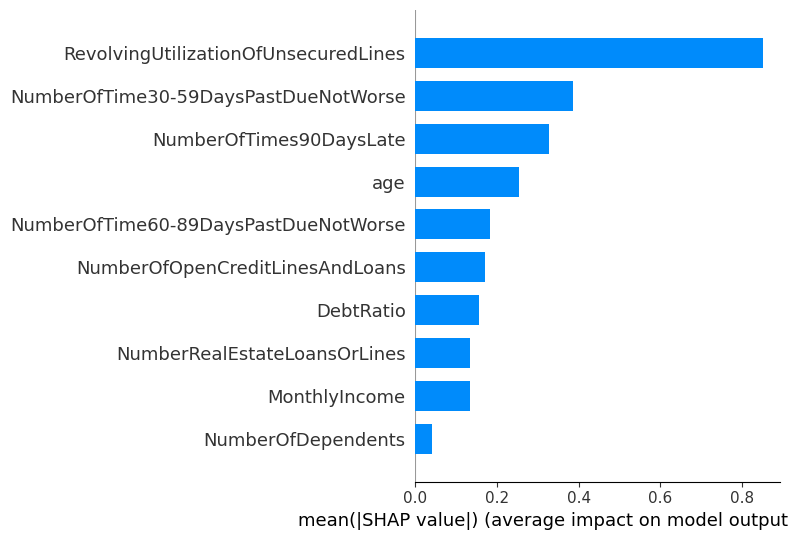

In [11]:
# Colab: !pip install shap
import shap
explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test)
shap.summary_plot(shap_values, X_test, plot_type="bar", show=True)

**Bulgu:** SHAP en üstte `RevolvingUtilization`, sonra gecikme özellikleri, sonra `age` - IV sıralamasıyla örtüşüyor. Model, bir kredi uzmanının bakacağı sinyallere (kredi kullanımı + ödeme geçmişi) bakıyor. Bu, modelin *denetlendiğinin* kanıtı.

### Lokal açıklama - tek riskli başvuru (LLM'in girdisi)

In [12]:
riskli_idx = int(np.argmax(y_proba_xgb))
feature_names = X_test.columns.tolist()
row_vals = X_test.iloc[riskli_idx].values
row_shap = shap_values[riskli_idx]

katkilar = sorted(zip(feature_names, row_vals, row_shap), key=lambda z: abs(z[2]), reverse=True)[:5]
print(f"Temerrüt olasılığı: {y_proba_xgb[riskli_idx]:.2f}\n")
for isim, deger, katki in katkilar:
    yon = "riski ARTIRDI" if katki > 0 else "riski azalttı"
    print(f"{isim:38s} | değer={deger:8.2f} | {yon} (SHAP={katki:+.3f})")

Temerrüt olasılığı: 0.99

NumberOfTimes90DaysLate                | değer=    7.00 | riski ARTIRDI (SHAP=+2.681)
NumberOfTime60-89DaysPastDueNotWorse   | değer=    1.00 | riski ARTIRDI (SHAP=+1.021)
NumberOfTime30-59DaysPastDueNotWorse   | değer=    1.00 | riski ARTIRDI (SHAP=+0.483)
MonthlyIncome                          | değer= 2846.00 | riski ARTIRDI (SHAP=+0.249)
RevolvingUtilizationOfUnsecuredLines   | değer=    0.00 | riski azalttı (SHAP=-0.166)


**Bulgu:** Seçilen müşteri (olasılık 0.99) - 90+ gün gecikmeyi **7 kez** yaşamış (SHAP en yüksek katkı), buna karşılık kredi kullanım oranı 0 olduğu için o faktör *riski azaltmış*. Temizlik sonrası açıklama artık bozuk DebtRatio'ya değil, gerçekçi ödeme geçmişi faktörlerine dayanıyor. Model dengeli: bazı faktörler riski artırırken diğerleri lehe çalışıyor.

## 10. LLM ile Sade Türkçe Gerekçe
SHAP çıktısı teknik. Groq + Llama-3.3 ile müşteriye gösterilebilir bir gerekçeye çeviriyoruz. Colab: `!pip install groq` + `GROQ_API_KEY`'i Secrets'a eklemek gerekiyor.

In [13]:
!pip install groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.7/143.7 kB 9.4 MB/s eta 0:00:00


In [14]:
# Colab: !pip install groq
from groq import Groq
from google.colab import userdata

tr_isim = {
    "RevolvingUtilizationOfUnsecuredLines": "kredi/limit kullanım oranı",
    "age": "yaş",
    "NumberOfTime30-59DaysPastDueNotWorse": "30-59 gün ödeme gecikmesi sayısı",
    "DebtRatio": "borç/gelir oranı",
    "MonthlyIncome": "aylık gelir",
    "NumberOfOpenCreditLinesAndLoans": "açık kredi/hesap sayısı",
    "NumberOfTimes90DaysLate": "90+ gün ödeme gecikmesi sayısı",
    "NumberRealEstateLoansOrLines": "gayrimenkul kredisi sayısı",
    "NumberOfTime60-89DaysPastDueNotWorse": "60-89 gün ödeme gecikmesi sayısı",
    "NumberOfDependents": "bakmakla yükümlü kişi sayısı",
}
satirlar = [f"- {tr_isim[i]}: değer {d:.2f}" for i, d, k in katkilar if k > 0]
ozet = "\n".join(satirlar)

prompt = f"""Bir kredi risk modeli, bir başvuruyu yüksek riskli buldu.
Kararı en çok etkileyen ve riski artıran faktörler:
{ozet}

Bu faktörlere dayanarak başvurana yönelik kısa (2-3 cümle), kibar ve anlaşılır
bir Türkçe gerekçe yaz. Teknik terim (model, SHAP, skor) kullanma."""

client = Groq(api_key=userdata.get("GROQ_API_KEY"))
resp = client.chat.completions.create(
    model="llama-3.3-70b-versatile",
    messages=[{"role": "user", "content": prompt}],
    temperature=0.3,
)
print(resp.choices[0].message.content)

Başvurunuzun değerlendirilmesi sırasında, geçmiş ödeme performansınızın beklentilerin altında olduğu görüldü. Özellikle son dönemde yaşanan 90+ gün ödeme gecikmeleri, kredi alma kararını olumsuz etkileyen önemli bir faktör oldu. Aylık geliriniz de kredi geri ödeme kapasitenizi tam olarak karşılamıyor gibi görünüyor.


**Örnek çıktı (bu çalıştırmada):**
> *Başvurunuzun değerlendirilmesi sırasında, geçmiş ödeme performansınızın beklentilerin altında olduğu görüldü. Özellikle son dönemde yaşanan 90+ gün ödeme gecikmeleri, kredi alma kararını olumsuz etkileyen önemli bir faktör oldu. Aylık geliriniz de kredi geri ödeme kapasitenizi tam olarak karşılamıyor gibi görünüyor.*

Gerekçe, müşterinin gerçek en güçlü SHAP faktörlerine (90+ gün gecikme + düşük gelir) dayanıyor; kibar ve teknik terim içermiyor. ML (skor) + SHAP (neden) + LLM (Türkçe gerekçe) tek boru hattında projeyi jenerik bir Kaggle notebook'undan ayıran kısım budur.

## 11. MLflow - Deney Takibi
Her modelin parametre ve metriklerini kaydediyoruz: reproducibility, karşılaştırma, "bu modeli hangi ayarla ürettim" sorusunun cevabı.

In [16]:
 !pip install mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 77.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.5/3.5 MB 72.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 68.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 19.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 97.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 12.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 212.0/212.0 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.3/121.3 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132

In [17]:
# Colab: !pip install mlflow
import mlflow
mlflow.set_experiment("kredi-risk-skorlama")

for ad, prob, params in [
    ("logistic", y_proba, {"model":"LogisticRegression","class_weight":"balanced"}),
    ("xgboost",  y_proba_xgb, {"model":"XGBoost","max_depth":4,"n_estimators":300}),
]:
    with mlflow.start_run(run_name=ad):
        mlflow.log_params(params)
        a = roc_auc_score(y_test, prob)
        mlflow.log_metrics({"AUC": a, "Gini": 2*a-1,
                            "PR_AUC": average_precision_score(y_test, prob),
                            "KS": ks_2samp(prob[y_test==1], prob[y_test==0]).statistic})
print("İki model de MLflow'a loglandı.")

2026/07/27 22:39:25 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/07/27 22:39:25 INFO mlflow.store.db.utils: Updating database tables
2026/07/27 22:39:28 INFO mlflow.tracking.fluent: Experiment with name 'kredi-risk-skorlama' does not exist. Creating a new experiment.


İki model de MLflow'a loglandı.


**Bulgu:** İki model de loglandı; yanda `mlflow.db` oluştu. `!mlflow ui` ile arayüzden run'ları yan yana karşılaştırabiliriz.

---
## Özet - Sonuçlar

| Model | AUC | Gini | KS | PR-AUC |
|-------|-----|------|----|--------|
| Logistic (temizlik öncesi) | 0.802 | 0.604 | 0.457 | 0.323 |
| Logistic (temizlik sonrası) | 0.834 | 0.668 | 0.509 | 0.335 |
| **XGBoost** | **0.866** | **0.732** | **0.577** | **0.401** |

**Ana çıkarımlar:**
1. Veri kalitesi denetimi (DebtRatio) baseline KS'ini 0.46→0.51 çıkardı.
2. IV ve SHAP çoğu özellikte örtüştü; ayrıştıkları yerin (sıfır-ağırlıklı sayaçlar) nedenini biliyoruz.
3. XGBoost en iyi model ama SHAP+LLM ile açıklanabilir kılındı → regülasyona uygun.


> *Açıklanabilir kredi risk skorlama modeli - veri kalitesi denetimi, IV ile feature selection, dengesiz veri (class_weight / scale_pos_weight), KS/Gini/PR-AUC değerlendirmesi, Logistic→XGBoost karşılaştırması, SHAP tabanlı red gerekçeleri + LLM ile Türkçe açıklama, MLflow ile deney takibi.*

**İleride eklenebilir:** WOE tabanlı scorecard (klasik puan kartı), hiperparametre optimizasyonu, sayaç özellikleri için özel binning.